# 01 — Bond Pricing : évaluation d'une obligation

Ce notebook illustre les fondements de l'évaluation obligataire :
1. Construction des flux de trésorerie d'une obligation à coupons.
2. Calcul du prix par actualisation des flux.
3. Vérification de trois cas fondamentaux : obligation au pair, zéro-coupon, inversion prix → YTM.
4. Visualisation de la relation prix-rendement et mise en évidence de la convexité.
5. Effet de la maturité sur la sensibilité du prix aux taux.

**Formule centrale :** $P = \sum_{i=1}^{n} \dfrac{CF_i}{(1+y)^{t_i}}$

## 1. Imports et configuration

On ajoute `../src` au chemin Python pour importer les fonctions maison du module `bonds` :
- `cashflows(nominal, coupon_rate, maturity)` : génère les dates `t` et les flux `cf`.
- `bond_price(t, cf, y)` : actualise chaque flux au taux `y` et somme.
- `ytm(t, cf, price)` : inverse la relation prix → rendement (TRI obligataire).

`numpy`, `pandas` et `matplotlib` servent respectivement au calcul vectoriel, à la restitution tabulaire et à la visualisation.

In [20]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bonds import cashflows, bond_price, ytm

## 2. Construction des flux de l'obligation

Une obligation est une **séquence de flux datés** : des coupons périodiques $C = c \times N$, et le remboursement du nominal $N$ à l'échéance (regroupé avec le dernier coupon).

Ici : nominal = 100, coupon = 5 %, maturité = 5 ans.

| Année | Flux |
|-------|------|
| 1 à 4 | 5 (coupon) |
| 5     | 105 (coupon + nominal) |

In [21]:
t, cf = cashflows(nominal=100, coupon_rate=0.05, maturity=5)
pd.DataFrame({"t (années)": t, "flux": cf})

,t (années),flux
0,1.0,5.0
1,2.0,5.0
2,3.0,5.0
3,4.0,5.0
4,5.0,105.0


## 3. Trois cas fondamentaux de pricing

**a) Obligation au pair.** Lorsque le taux de marché égale le taux de coupon ($y = c$), le prix doit être exactement le nominal. C'est un test de cohérence du modèle.

**b) Zéro-coupon.** Avec $c = 0$, un seul flux subsiste : le nominal en $t = n$. Le prix se réduit à $N(1+y)^{-n}$. On compare le calcul générique à la formule analytique.

**c) Inversion prix → YTM.** On calcule un prix à $y = 3\%$, puis on vérifie que `ytm()` retrouve bien 3 %. Cela démontre que le YTM est le taux unique qui égalise la valeur actuelle des flux au prix de marché.

In [16]:
# 1. Obligation au pair
print("Au pair (100) :", bond_price(t, cf, 0.05))

# 2. Zéro-coupon
t0, cf0 = cashflows(100, 0.0, 5)
print("ZC :", bond_price(t0, cf0, 0.04), "| formule :", 100 / 1.04**5)

# 3. Aller-retour prix -> YTM
p = bond_price(t, cf, 0.03)
print("Prix à 3 % :", p, "| YTM retrouvé :", ytm(t, cf, p))

Au pair (100) : 99.99999999999997
ZC : 82.19271067593517 | formule : 82.19271067593517
Prix à 3 % : 109.15941437438906 | YTM retrouvé : 0.03000000002939486


## 4. Courbe prix-rendement

On trace le prix pour $y$ balayé de 0 % à 15 %. Observations attendues :
- **Décroissance** : quand les taux montent, le prix baisse (actualisation plus forte).
- **Convexité** : la courbe est convexe (dérivée seconde positive), ce qui implique une asymétrie : une baisse de taux fait plus monter le prix qu'une hausse équivalente ne le fait baisser.
- **Point au pair** : la courbe croise la ligne $P = 100$ exactement à $y = 5\%$ (ligne pointillée).

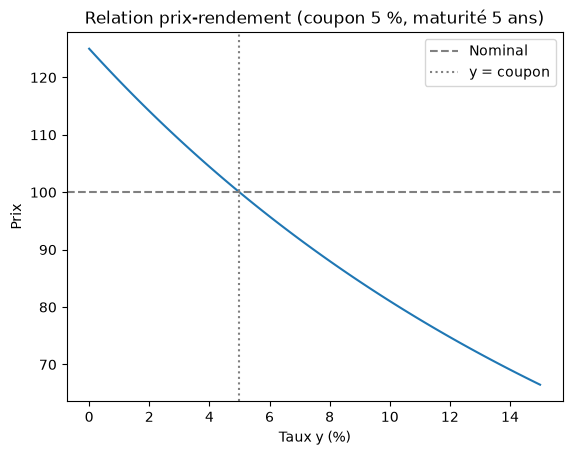

In [17]:
ys = np.linspace(0.0, 0.15, 100)
prices = [bond_price(t, cf, y) for y in ys]

plt.plot(ys * 100, prices)
plt.axhline(100, color="gray", linestyle="--", label="Nominal")
plt.axvline(5, color="gray", linestyle=":", label="y = coupon")
plt.xlabel("Taux y (%)")
plt.ylabel("Prix")
plt.title("Relation prix-rendement (coupon 5 %, maturité 5 ans)")
plt.legend()
plt.show()

## 5. Effet de la maturité sur la sensibilité

On compare deux obligations de même coupon (5 %) mais de maturités très différentes (2 ans vs 20 ans), évaluées à deux taux (3 % et 7 %). Objectif : mesurer l'**effet de maturité sur la sensibilité au taux**.

Observations attendues :
- À 3 %, l'obligation 20 ans cote bien au-dessus du pair (car son coupon de 5 % est supérieur au taux de marché) — cette prime se cumule sur 20 ans.
- À 7 %, c'est l'inverse : l'obligation 20 ans souffre davantage, ses coupons « faibles » étant pénalisés plus longtemps.
- Lien direct avec la **duration** : plus la maturité est longue, plus le prix est sensible aux variations de taux.

In [18]:
rows = []
for maturity in [2, 20]:
    t_, cf_ = cashflows(100, 0.05, maturity)
    for y in [0.03, 0.07]:
        rows.append({"maturité": maturity, "y": y, "prix": bond_price(t_, cf_, y)})

df = pd.DataFrame(rows)
df

,maturité,y,prix
0,2,0.03,103.826939
1,2,0.07,96.383964
2,20,0.03,129.754950
3,20,0.07,78.811972


## 6. Quantification de la sensibilité

On transforme les niveaux de prix en **variations relatives** pour comparer les maturités.

Pour une hausse de taux de +4 points (3 % → 7 %), on s'attend à :
- une perte modérée pour la 2 ans ;
- une perte beaucoup plus forte pour la 20 ans.

Cela illustre la **duration modifiée** :
$$D_{mod} = -\frac{1}{P}\frac{\partial P}{\partial y}$$
et l'approximation :
$$\frac{\Delta P}{P} \approx -D_{mod}\,\Delta y + \frac{1}{2}\,C\,(\Delta y)^2$$
où $C$ est la convexité.

In [19]:
for maturity in [2, 20]:
    t_, cf_ = cashflows(100, 0.05, maturity)
    p3 = bond_price(t_, cf_, 0.03)
    p7 = bond_price(t_, cf_, 0.07)
    print(f"Maturité {maturity} ans : {100 * (p7 / p3 - 1):.1f} %")

Maturité 2 ans : -7.2 %
Maturité 20 ans : -39.3 %
